# Libraries

To run this you need the libraries below. You just need to install the with `pip`. If you want to know more about `andi_datasets`, visit this [link](https://andichallenge.github.io/andi_datasets/).

In [217]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from andi_datasets.analysis import dataset_angles, get_angle

In [218]:
from andi_datasets.analysis import msd_analysis
mda = msd_analysis()

In [219]:
def get_trajs(df, max_t = None):
    trajs = []
    for _, group in df.groupby('Track ID', sort=False):
        x = group.X.values.astype(float)
        #x -= x[0]
        y = group.Y.values.astype(float)
        #y -= y[0]
        trajs.append(np.vstack((x[:max_t],y[:max_t])))
        
    return trajs

# Angles

First load trajectories + create BM trajectoies as control for testing

In [220]:
dataframe = pd.read_csv(f'Flat.csv',  header = 2)[1:].sort_values(['Track ID', 'Frame'])

trajs = np.array(get_trajs(dataframe, max_t = 10)).transpose(0,2,1)
Ds = mda.get_diff_coeff(trajs)

Ds.shape

(166,)

In [54]:
i = 1
flat = pd.read_csv(f'Flat.csv', 
                   header = 2)[1:].sort_values(['Track ID', 'Frame'])
ridge = pd.read_csv('Ridges.csv', 
                    header = 2)[1:].sort_values(['Track ID', 'Frame'])

trajs_f = get_trajs(flat)
trajs_r = get_trajs(ridge)

# BM trajectories
control = np.random.randn(1000, 2, 20).cumsum(-1)

Calculate angles

In [ ]:
ang = andi_datasets.analysis.dataset_angles(trajs_f)
angles_r = dataset_angles(trajs_r)
angles_c = dataset_angles(control)

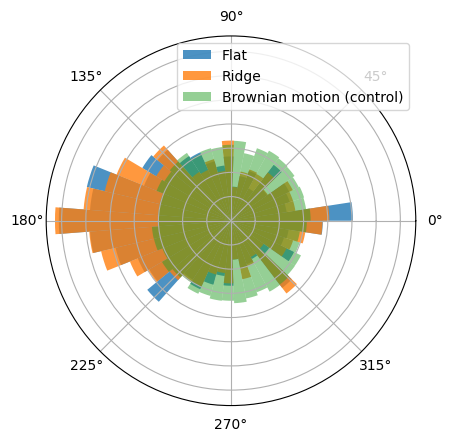

In [ ]:
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})


ang = andi_datasets.analysis.dataset_angles(trajs_f)
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
plt.ax(2*np.pi*np.array(ang)/360)
ax.legend()
    
plt.setp(ax, yticklabels=[]);

fig.savefig('plot_angles.svg')

# MSD

We perform now the extraction of diffusion coefficient from the MSD

## 2D diffusion

In [225]:
trajs_f = np.array(get_trajs(flat, max_t = 10)).transpose(0,2,1)
trajs_r = np.array(get_trajs(ridge, max_t = 10)).transpose(0,2,1)

In [226]:
trajs_f.shape

(166, 10, 2)

In [227]:
D_f = mda.get_diff_coeff(trajs_f)
D_r = mda.get_diff_coeff(trajs_r)

Let's take a look at the mean D for each experiment:

In [228]:
D_f.mean(), D_r.mean()

(29.390705058329008, 23.231540285115283)

And plot their distributions:

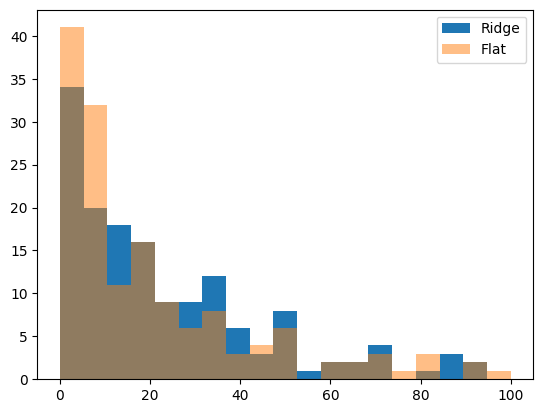

In [60]:
plt.hist(D_f, bins = np.linspace(0,100,20), label = 'Ridge')
plt.hist(D_r, alpha = 0.5, bins = np.linspace(0,100,20), label = 'Flat')

plt.legend();

## Separated by dimension
We now do the same as above but we separate the two dimensions.

In [61]:
trajs_f = np.array(get_trajs(flat, max_t = 10)).transpose(0,2,1)
trajs_r = np.array(get_trajs(ridge, max_t = 10)).transpose(0,2,1)

So the the spatial dimensions are in the last dimension of the previous tensor, hence X is in the `[:,:,0]`, and Y in `[:,:,1]`. Below we do this but with `[:1]` and `[1:]` (same as before), but allowing us to keep the dimensions consistent.

In [229]:
t_lags = [1,2,3,4]
D_f = mda.get_diff_coeff(trajs_f, t_lags = t_lags)
D_r = mda.get_diff_coeff(trajs_r, t_lags = t_lags)

D_fx = msd_analysis().get_diff_coeff(trajs_f[:,:,:1], t_lags = t_lags)
D_fy = msd_analysis().get_diff_coeff(trajs_f[:,:,1:], t_lags = t_lags)

D_rx = msd_analysis().get_diff_coeff(trajs_r[:,:,:1], t_lags = t_lags)
D_ry = msd_analysis().get_diff_coeff(trajs_r[:,:,1:], t_lags = t_lags)

# D_fx = D_fx[D_fx > 0]
# D_fy = D_fy[D_fy > 0]
# D_rx = D_rx[D_rx > 0]
# D_ry = D_ry[D_ry > 0]

In [230]:
D_f.mean(), D_r.mean()

(29.690824837789304, 24.407996965870968)

In [231]:
D_fx.mean(), D_fy.mean()

(28.939324277564637, 30.442325398013974)

In [232]:
D_rx.mean(), D_ry.mean()

(36.1297240051716, 12.68626992657033)

In [43]:
Ds_fiji = pd.read_csv('save_D.csv', index_col=0)

In [47]:
D_f

array([ 4.91642845e+01,  3.55193575e+01,  1.78288428e+01,  8.65119827e+00,
        1.80316809e+00,  1.27421081e+00, -4.16548352e+00,  8.53014680e+01,
        1.92589731e+01,  3.37664828e+00, -8.29911871e-01,  6.97041859e+00,
        1.73996376e+01,  3.48453834e+01,  3.46383247e+00,  6.64096396e+00,
        1.45603320e+01,  7.95038157e+00,  6.75749200e+00,  2.27627436e+00,
        4.76486391e+00,  1.60156112e+01,  1.95125855e+01,  2.16095561e+01,
        3.72118830e+01,  3.84919571e+01,  4.22282348e+01,  4.83922154e+01,
        3.16824960e+01,  2.75262236e+01,  5.81415833e+01,  3.92028194e+01,
        5.43885292e+00, -1.29935694e-01,  1.08198648e+01,  4.84844240e+01,
        1.92790866e+01,  4.97192160e+00,  1.70287746e+02,  1.22281938e+01,
        1.43384155e+01,  2.25065257e+01,  1.63668569e+01,  1.63517651e+01,
        1.52359938e+01,  3.00562066e+01,  1.70366517e+01,  1.00703449e+02,
        1.94065231e+00,  1.05734036e+01, -1.00596792e-02,  3.62428066e+01,
        8.83847225e+01,  

In [46]:
Ds_fiji.D_2d.values

array([ 5.023981e+01,  4.026762e+01,           nan,  1.818741e+01,
        3.130997e+00,  2.669095e+01,  4.130603e+00,  5.532349e+01,
                 nan,  6.267509e+01,  2.049979e+01,  2.708449e+01,
        9.758881e+00,  3.043899e+01,  8.716723e+00,           nan,
        2.700677e+01,  9.697988e+00,  3.180938e+00,  4.026360e+01,
                 nan,  2.624699e+01,  9.735270e+00,  2.894405e+01,
        4.567717e+01,           nan,  6.468503e+01,           nan,
                 nan,  3.071729e+01,  2.040193e+01,  3.250371e+01,
        2.989905e-01,  8.368301e-02,  2.878124e+01,           nan,
        8.634049e+01,  2.101611e+01,           nan,  8.007113e+00,
                 nan,  1.092008e+01,           nan,  2.308309e+01,
        2.857354e+01,           nan,  9.584679e+01,           nan,
        4.638997e+00,  4.414054e+00,  1.724301e+00,  4.329484e+01,
        1.204402e+01,           nan,           nan,  3.692996e+01,
                 nan,  2.161220e+01,  1.778484e+01,           

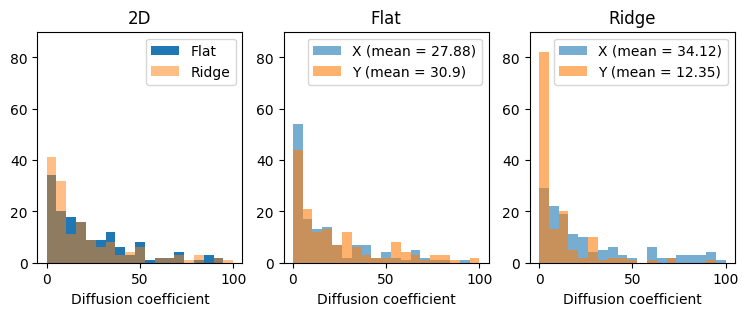

In [19]:
fig, ax = plt.subplots(1, 3, figsize = (9,3))

ax[0].hist(D_f, bins = np.linspace(0,100,20), label = 'Flat')
ax[0].hist(D_r, alpha = 0.5, bins = np.linspace(0,100,20), label = 'Ridge')
ax[0].legend()
ax[0].set_title('2D')

ax[1].hist(D_fx, alpha = 0.6, bins = np.linspace(0,100,20), 
           label = f'X (mean = {np.round(D_fx.mean(),2)})')
ax[1].hist(D_fy, alpha = 0.6, bins = np.linspace(0,100,20),
           label = f'Y (mean = {np.round(D_fy.mean(),2)})')
ax[1].legend()
ax[1].set_title('Flat')

ax[2].hist(D_rx, alpha = 0.6, bins = np.linspace(0,100,20), 
           label = f'X (mean = {np.round(D_rx.mean(),2)})')
ax[2].hist(D_ry, alpha = 0.6, bins = np.linspace(0,100,20),
           label = f'Y (mean = {np.round(D_ry.mean(),2)})')
ax[2].set_title('Ridge')
ax[2].legend()

plt.setp(ax, ylim = (0, 90), xlabel = 'Diffusion coefficient');

In [20]:
D_rx.std()/np.sqrt(D_rx.shape[0])

4.239591039377334

In [21]:
D_fx.std()/np.sqrt(D_fx.shape[0])

3.5971165499581677

# Anomalous exponent

In [22]:
trajs_f = np.array(get_trajs(flat, max_t = 10)).transpose(0,2,1)
trajs_r = np.array(get_trajs(ridge, max_t = 10)).transpose(0,2,1)

So the the spatial dimensions are in the last dimension of the previous tensor, hence X is in the `[:,:,0]`, and Y in `[:,:,1]`. Below we do this but with `[:1]` and `[1:]` (same as before), but allowing us to keep the dimensions consistent.

In [24]:
t_lags = np.arange(4,10).tolist()

a_f = mda.get_exponent(trajs_f, t_lags = t_lags)
a_r = mda.get_exponent(trajs_r, t_lags = t_lags)


a_fx = mda.get_exponent(trajs_f[:,:,:1], t_lags = t_lags)
a_fy = mda.get_exponent(trajs_f[:,:,1:], t_lags = t_lags)

a_rx = mda.get_exponent(trajs_r[:,:,:1], t_lags = t_lags)
a_ry = mda.get_exponent(trajs_r[:,:,1:], t_lags = t_lags)

# a_fx = a_fx[a_fx > 0]
# a_fy = a_fy[a_fy > 0]
# a_rx = a_rx[a_rx > 0]
# a_ry = a_ry[a_ry > 0]

c:\Users\Gorka\anaconda3\envs\andi\lib\site-packages\andi_datasets\analysis.py:137: RuntimeWarning: divide by zero encountered in log
  return np.polyfit(np.log(t_lags), np.log(tasmd), deg = 1)[0]


In [25]:
a_fx.mean(), a_fy.mean()

(nan, -0.1351786993599633)

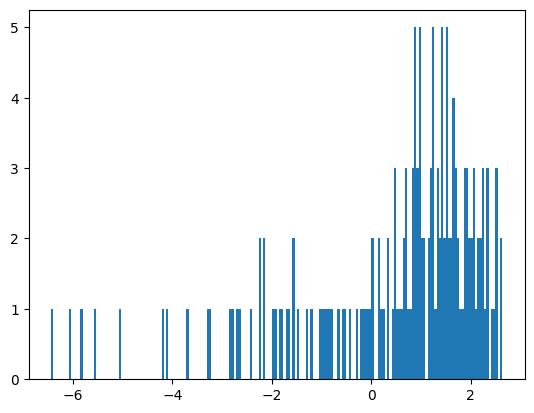

In [26]:
plt.hist(a_fy[a_fy> -10], bins = 200);

c:\Users\Gorka\anaconda3\envs\andi\lib\site-packages\matplotlib\axes\_axes.py:6831: RuntimeWarning: All-NaN slice encountered
  xmin = min(xmin, np.nanmin(xi))
c:\Users\Gorka\anaconda3\envs\andi\lib\site-packages\matplotlib\axes\_axes.py:6832: RuntimeWarning: All-NaN slice encountered
  xmax = max(xmax, np.nanmax(xi))


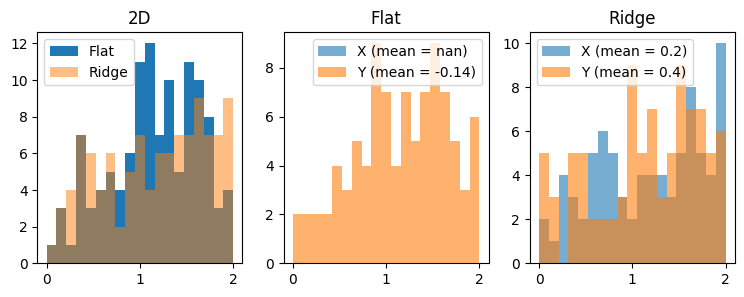

In [27]:
fig, ax = plt.subplots(1, 3, figsize = (9,3))

bins_a = np.linspace(0,2,20)

ax[0].hist(a_f, bins = bins_a, label = 'Flat')
ax[0].hist(a_r, alpha = 0.5, bins = bins_a, label = 'Ridge')
ax[0].legend()
ax[0].set_title('2D')

ax[1].hist(a_fx, alpha = 0.6, bins = bins_a, 
           label = f'X (mean = {np.round(a_fx.mean(),2)})')
ax[1].hist(a_fy, alpha = 0.6, bins = bins_a,
           label = f'Y (mean = {np.round(a_fy.mean(),2)})')
ax[1].legend()
ax[1].set_title('Flat')

ax[2].hist(a_rx, alpha = 0.6, bins = bins_a, 
           label = f'X (mean = {np.round(a_rx.mean(),2)})')
ax[2].hist(a_ry, alpha = 0.6, bins = bins_a,
           label = f'Y (mean = {np.round(a_ry.mean(),2)})')
ax[2].set_title('Ridge')
ax[2].legend()

# plt.setp(ax, ylim = (0, 2), xlabel = 'Anomalous exponent');

# Ensemble TMSD

In [28]:
t_lags = np.arange(1, trajs_f.shape[1])
tmsd_f = mda.tamsd(trajs_f, t_lags = t_lags, dim = 2)
tmsd_r = mda.tamsd(trajs_r, t_lags = t_lags, dim = 2)

In [29]:
t_lags

array([1, 2, 3, 4, 5, 6, 7, 8, 9])

In [30]:
alpha_f = np.polyfit(np.log(t_lags), np.log(tmsd_f.mean(1)), deg = 1)[0]
alpha_r = np.polyfit(np.log(t_lags), np.log(tmsd_r.mean(1)), deg = 1)[0]

In [31]:
alpha_f, alpha_r

(1.1325132338133004, 1.1576818261097923)

(60.440452253205876, 2000.0)

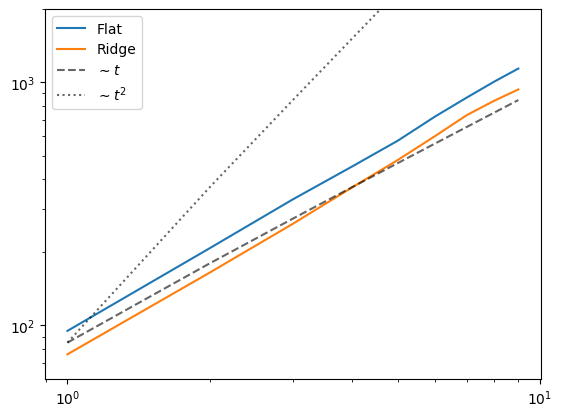

In [32]:
plt.loglog(t_lags, tmsd_f.mean(1), label = 'Flat')
plt.plot(t_lags, tmsd_r.mean(1), label = 'Ridge')

plt.plot(t_lags, t_lags*tmsd_f[0].mean()-10, ls = '--', c = 'k',  label = r'$\sim t$', alpha = 0.6)
plt.plot(t_lags, t_lags**2*tmsd_f[0].mean()-10, ls = ':', c = 'k', label = r'$\sim t^2$', alpha = 0.6)

plt.legend()
plt.ylim(ymax = 2e3)

## Separated by dimensions

In [33]:
tmsd_fx = mda.tamsd(trajs_f[:,:,:1], t_lags = t_lags, dim = 2)
tmsd_fy = mda.tamsd(trajs_f[:,:,1:], t_lags = t_lags, dim = 2)

tmsd_rx = mda.tamsd(trajs_r[:,:,:1], t_lags = t_lags, dim = 2)
tmsd_ry = mda.tamsd(trajs_r[:,:,1:], t_lags = t_lags, dim = 2)

In [34]:
alpha_fx = np.polyfit(np.log(t_lags), np.log(tmsd_fx.mean(1)), deg = 1)[0]
alpha_fy = np.polyfit(np.log(t_lags), np.log(tmsd_fy.mean(1)), deg = 1)[0]

alpha_rx = np.polyfit(np.log(t_lags), np.log(tmsd_rx.mean(1)), deg = 1)[0]
alpha_ry = np.polyfit(np.log(t_lags), np.log(tmsd_ry.mean(1)), deg = 1)[0]


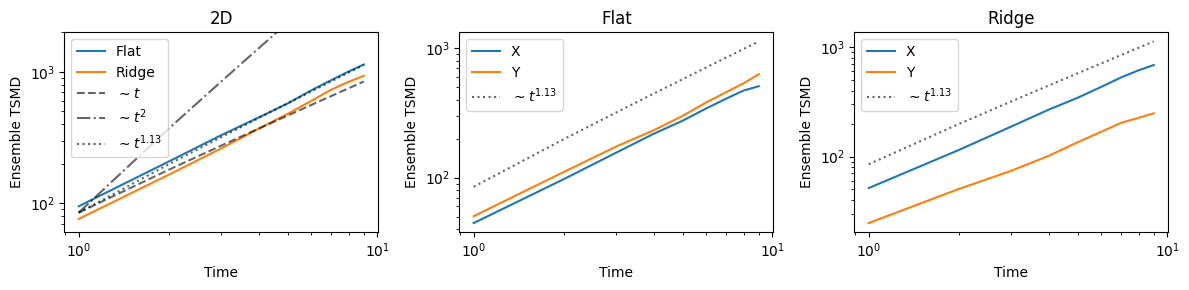

In [35]:
fig, ax = plt.subplots(1, 3, figsize = (12,3), tight_layout = True)



ax[0].loglog(t_lags, tmsd_f.mean(1), label = 'Flat')
ax[0].plot(t_lags, tmsd_r.mean(1), label = 'Ridge')
ax[0].plot(t_lags, t_lags*tmsd_f[0].mean()-10, ls = '--', c = 'k',  label = r'$\sim t$', alpha = 0.6)
ax[0].plot(t_lags, t_lags**2*tmsd_f[0].mean()-10, ls = '-.', c = 'k', label = r'$\sim t^2$', alpha = 0.6)
ax[0].set_title('2D')
ax[0].set_ylim(ymax = 2e3)

ax[1].loglog(t_lags, tmsd_fx.mean(1), label = 'X')
ax[1].plot(t_lags, tmsd_fy.mean(1), label = 'Y')
ax[1].set_title('Flat')

ax[2].loglog(t_lags, tmsd_rx.mean(1), label = 'X')
ax[2].plot(t_lags, tmsd_ry.mean(1), label = 'Y')
ax[2].set_title('Ridge')


for a in ax:
    a.plot(t_lags, t_lags**1.13*tmsd_f[0].mean()-10, ls = ':', c = 'k', label = r'$\sim t^{1.13}$', alpha = 0.6)

ax[0].legend()
ax[1].legend()
ax[2].legend()


plt.setp(ax, xlabel = 'Time', ylabel = 'Ensemble TSMD');

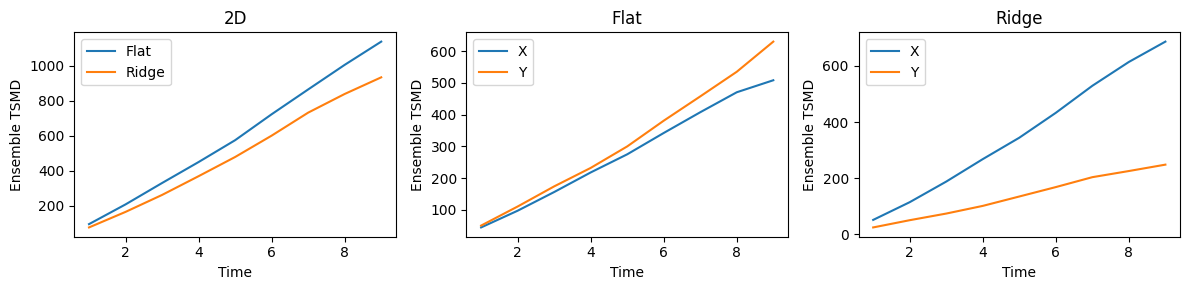

In [36]:
fig, ax = plt.subplots(1, 3, figsize = (12,3), tight_layout = True)



ax[0].plot(t_lags, tmsd_f.mean(1), label = 'Flat')
ax[0].plot(t_lags, tmsd_r.mean(1), label = 'Ridge')
ax[0].set_title('2D')

ax[1].plot(t_lags, tmsd_fx.mean(1), label = 'X')
ax[1].plot(t_lags, tmsd_fy.mean(1), label = 'Y')
ax[1].set_title('Flat')

ax[2].plot(t_lags, tmsd_rx.mean(1), label = 'X')
ax[2].plot(t_lags, tmsd_ry.mean(1), label = 'Y')
ax[2].set_title('Ridge')


# for a in ax:
#     a.plot(t_lags, t_lags**1.13*tmsd_f[0].mean()-10, ls = ':', c = 'k', label = r'$\sim t^{1.13}$', alpha = 0.6)

ax[0].legend()
ax[1].legend()
ax[2].legend()


plt.setp(ax, xlabel = 'Time', ylabel = 'Ensemble TSMD');

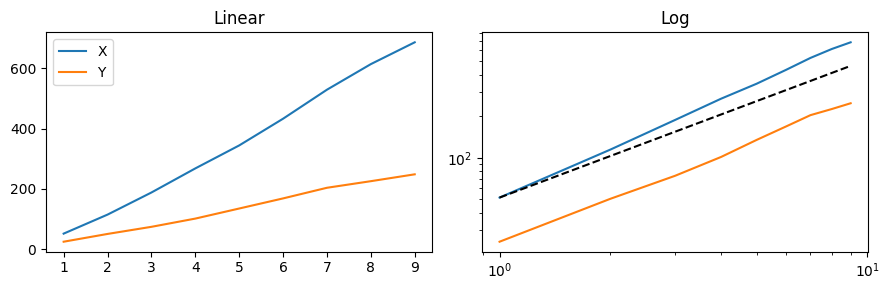

In [37]:
fig, ax = plt.subplots(1, 2, figsize = (9,3), tight_layout = True)


ax[0].plot(t_lags, tmsd_rx.mean(1), label = 'X')
ax[0].plot(t_lags, tmsd_ry.mean(1), label = 'Y')
ax[0].set_title('Linear')
ax[0].legend()

ax[1].loglog(t_lags, tmsd_rx.mean(1), label = 'X')
ax[1].plot(t_lags, tmsd_ry.mean(1), label = 'Y')
ax[1].set_title('Log')

ax[1].plot(t_lags, t_lags*tmsd_rx.mean(1)[0], c = 'k', ls = '--')

# Debugging fiji

In [98]:
first_three = dataframe['Track ID'].unique()[:3]
df = dataframe.loc[dataframe['Track ID'].isin(first_three)]

In [ ]:
df = pd.read_csv(f'Flat.csv',  header = 2)[1:].sort_values(['Track ID', 'Frame'])
trajs = get_trajs(df)
#D_f = mda.get_diff_coeff(trajs_f)



In [210]:
t_lags = [1,2,3,4,5,6]
val_D, val_Dx, val_Dy = [], [], []
for t in trajs:
    t = t.transpose()[np.newaxis,:,:]
    D = mda.get_diff_coeff(t, t_lags = t_lags)
    D_x = msd_analysis().get_diff_coeff(t[:,:,:1], t_lags = t_lags)
    D_y = msd_analysis().get_diff_coeff(t[:,:,1:], t_lags = t_lags)
    val_D.append(D[0])
    val_Dx.append(D_x[0])
    val_Dy.append(D_y[0])

    print(D, D_x, D_y)

np.mean(val_D), np.mean(val_Dx), np.mean(val_Dy)

[66.7631369] [60.0841025] [73.4421713]
[78.34824851] [124.22714916] [32.46934785]
[35.28056402] [21.14897154] [49.4121565]


(60.13064980958478, 68.48674106651889, 51.774558552650696)

In [197]:
# t_lag = [1,2]
Ds_fiji = pd.read_csv('save_D.csv', index_col=0)
Ds_fiji

,D_2d,D_x,D_y
traj_idx,,,
0,5.023981,5.085748,4.962215
3,4.026762,6.544530,1.508994
4,1.874125,1.149873,2.598377


In [216]:
t_lags = np.arange(1,7).tolist()
print(t_lags)
val_a, val_ax, val_ay = [], [], []
for t in trajs:
    t = t.transpose()[np.newaxis,:,:]
    alpha = mda.get_exponent(t, t_lags = t_lags)
    alpha_x = msd_analysis().get_exponent(t[:,:,:1], t_lags = t_lags)
    alpha_y = msd_analysis().get_exponent(t[:,:,1:], t_lags = t_lags)
    val_a.append(alpha[0])
    val_ax.append(alpha_x[0])
    val_ay.append(alpha_y[0])

    print(alpha, alpha_x, alpha_y)

np.mean(val_a), np.mean(val_ax), np.mean(val_ay)

[1, 2, 3, 4, 5, 6]
[1.44787923] [1.44217193] [1.45336274]
[1.40962435] [1.47191178] [1.22934246]
[1.64918611] [1.63527999] [1.6551704]


(1.502229897243728, 1.516454568949016, 1.4459585301852111)

In [ ]:
Ds_fiji = pd.read_csv('save_D.csv', index_col=0)
Ds_fiji

,D_2d,D_x,D_y
traj_idx,,,
0,50.23981,50.85748,49.62215
3,40.26762,65.44530,15.08994
4,18.74125,11.49873,25.98377
